# Modeling a 64-bit 2-XOR Arbiter PUF

**Machine-learning pipeline | Challenge–response preprocessing | Classical ML | Neural networks**

This project studies whether a model can predict the response of a 64-bit 2-XOR Arbiter Physical Unclonable Function (XOR-APUF) from observed challenge–response pairs (CRPs).

> **Project framing:** this is a *behavioral modeling attack* on the available CRP dataset. A high prediction score shows that the recorded input/output behavior is learnable under this data split; it does not, by itself, recover the PUF's physical delay parameters or establish a result for every physical device.

## Project at a glance

- **Task:** binary classification of PUF responses.
- **Input:** 64-bit hexadecimal challenges transformed into APUF parity features.
- **Target:** a binary response label derived from the response field in the source file.
- **Models:** linear baseline, dense neural network, and explicit quadratic 2-XOR feature model.
- **Evaluation:** training, validation, and held-out test sets; accuracy, precision, recall, F1, and a confusion matrix.

## Contents

1. [Problem formulation](#1-problem-formulation)
2. [Environment and dataset setup](#2-environment-and-dataset-setup)
3. [Load and inspect raw CRPs](#3-load-and-inspect-raw-crps)
4. [Create response labels and inspect data quality](#4-create-response-labels-and-inspect-data-quality)
5. [Challenge encoding and parity features](#5-challenge-encoding-and-parity-features)
6. [Train/validation/test split](#6-trainvalidationtest-split)
7. [Baseline: linear model](#7-baseline-linear-model)
8. [Neural network model](#8-neural-network-model)
9. [Explicit quadratic 2-XOR model](#9-explicit-quadratic-2-xor-model)
10. [Validation comparison and final test evaluation](#10-validation-comparison-and-final-test-evaluation)
11. [Interpretation, limitations, and next steps](#11-interpretation-limitations-and-next-steps)

## End-to-end pipeline

```text
Raw CRP text file
       ↓
Parse challenge IDs, challenge hex, response hex
       ↓
Aggregate response records per challenge → binary label
       ↓
Check class balance, repeated readings, and label reliability proxy
       ↓
Hex challenge → 64 bits in {-1, +1}
       ↓
APUF parity transform → 64 parity features
       ↓
Stratified 80% train / 10% validation / 10% test split
       ↓
Train candidate models using training data; compare on validation data
       ↓
Evaluate selected model family/finalists on untouched test data
```

## 1. Problem formulation

An Arbiter PUF produces a response based on the relative delay of two paths. In the common additive-delay model, the challenge is transformed into a parity feature vector \(\phi\), and a single APUF can be described as

\[
r_i = \operatorname{sign}(w_i^T\phi).
\]

A 2-XOR APUF combines the responses of two constituent APUFs. With responses represented in \(\{-1,+1\}\), the combined output can be written as

\[
r = \operatorname{sign}(w_1^T\phi)\operatorname{sign}(w_2^T\phi)
  = \operatorname{sign}\left[(w_1^T\phi)(w_2^T\phi)\right].
\]

Expanding the product creates quadratic interactions between parity features. That motivates the two main modeling routes used here:

- **Implicit nonlinear learning:** a dense neural network learns a nonlinear decision function from the parity features.
- **Explicit quadratic modeling:** construct pairwise products of parity features, then fit a linear classifier in that expanded feature space.

The underlying hardware's bit-order convention matters. This notebook uses the bit order produced by parsing the challenge hexadecimal string from most-significant to least-significant bit; verify this convention against the dataset documentation if comparing learned behavior to a specific hardware implementation.

## 2. Environment and dataset setup

### Raw dataset file

Place the dataset text file at the path configured below. The default path matches a Google Colab upload. If you use Kaggle or a local runtime, update `TXT_PATH` to your actual file location.

The parser expects semicolon-separated lines in this general form:

```text
iteration; challenge_id; challenge = HEX_CHALLENGE; HEX_RESPONSE
```

**Important data assumption:** the response-processing code treats each response token as a 32-bit word, computes the fraction of its bits that are `1`, averages this fraction across records with the same challenge ID, and thresholds at 0.5 to produce a binary label. Confirm that this interpretation matches the source dataset's response encoding before treating these labels as hardware ground truth. The source text file is not embedded in this GitHub notebook; obtain it separately and respect the dataset's terms.

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Update this path if you are not running in Google Colab.
TXT_PATH = Path("/content/2XOR_64bit_X0_Y0_virticle_223A5.txt")

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Dataset path:", TXT_PATH)

NumPy: 2.1.3
pandas: 2.2.3
TensorFlow: 2.21.0
Dataset path: /content/2XOR_64bit_X0_Y0_virticle_223A5.txt


## 3. Load and inspect raw CRPs

The first stage is data ingestion. Each valid line contributes a challenge ID, the hexadecimal challenge, and the hexadecimal response token. Basic counts are printed immediately so parsing issues are visible before any modeling begins.

In [2]:
if not TXT_PATH.exists():
    raise FileNotFoundError(
        f"Dataset file not found: {TXT_PATH}\n"
        "Upload the raw .txt file to this location, or update TXT_PATH to its location."
    )

records = []
skipped_lines = 0

with TXT_PATH.open("r", encoding="utf-8", errors="replace") as file:
    for line in file:
        parts = line.strip().split(";")
        if len(parts) < 4:
            skipped_lines += 1
            continue
        try:
            challenge_id = int(parts[1].strip())
            challenge_hex = parts[2].split("=", maxsplit=1)[1].strip()
            response_hex = parts[3].strip()
        except (ValueError, IndexError):
            skipped_lines += 1
            continue

        records.append((challenge_id, challenge_hex, response_hex))

df = pd.DataFrame(records, columns=["crp", "chal_hex", "resp_hex"])
if df.empty:
    raise ValueError("No valid CRP rows were parsed. Check TXT_PATH and the source file format.")

print(f"Parsed raw rows: {len(df):,}")
print(f"Unique challenge IDs: {df['crp'].nunique():,}")
print(f"Skipped malformed/unrecognized lines: {skipped_lines:,}")
display(df.head())

Parsed raw rows: 139,810
Unique challenge IDs: 60,000
Skipped malformed/unrecognized lines: 1


,crp,chal_hex,resp_hex
0,1,5851F42D00000000,FFFFFFFF
1,2,4BB5F64640B18CCF,FFFFFFFF
2,3,30705B0447033129,00000000
3,4,1A8B7F7820FD5DB4,FFFFFFFF
4,5,2B894868502959D8,00000000


## 4. Create response labels and inspect data quality

For each recorded response token, the fraction of set bits is calculated relative to a 32-bit word. Records sharing a challenge ID are then aggregated. The resulting mean fraction is thresholded at 0.5 to create the binary class label.

The `reliability` column is a simple distance-from-0.5 proxy derived from that aggregation. It is **not** a calibrated probability or a universal measure of physical PUF reliability.

In [3]:
# This step assumes each response token encodes a 32-bit word.
df["response_fraction"] = df["resp_hex"].apply(
    lambda h: bin(int(h, 16)).count("1") / 32.0
)

agg = (
    df.groupby("crp", as_index=False)
      .agg(
          chal_hex=("chal_hex", "first"),
          mean_response_fraction=("response_fraction", "mean"),
          n_readings=("resp_hex", "size"),
          n_distinct_challenges=("chal_hex", "nunique"),
      )
)

if not agg["n_distinct_challenges"].eq(1).all():
    raise ValueError("At least one challenge ID maps to more than one challenge hex string.")

agg["response"] = (agg["mean_response_fraction"] >= 0.5).astype(np.int8)
agg["reliability"] = np.where(
    agg["response"].eq(1),
    agg["mean_response_fraction"],
    1.0 - agg["mean_response_fraction"],
)

print(f"Aggregated challenge rows: {len(agg):,}")
print("Response class proportions:")
display(agg["response"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Repeated-record count summary:")
display(agg["n_readings"].describe().to_frame())
print(f"Median reliability proxy: {agg['reliability'].median():.4f}")

Aggregated challenge rows: 60,000
Response class proportions:


,proportion
response,
0,0.472183
1,0.527817


Repeated-record count summary:


,n_readings
count,60000.000000
mean,2.330167
std,0.470277
min,2.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,3.000000


Median reliability proxy: 1.0000


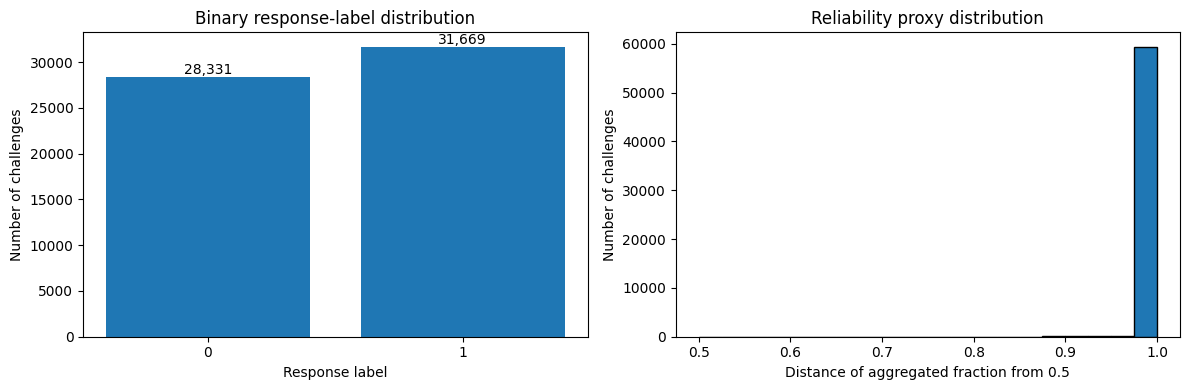

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

class_counts = agg["response"].value_counts().sort_index()
axes[0].bar(class_counts.index.astype(str), class_counts.values)
axes[0].set_title("Binary response-label distribution")
axes[0].set_xlabel("Response label")
axes[0].set_ylabel("Number of challenges")
for x, count in enumerate(class_counts.values):
    axes[0].text(x, count, f"{count:,}", ha="center", va="bottom")

axes[1].hist(agg["reliability"], bins=20, edgecolor="black")
axes[1].set_title("Reliability proxy distribution")
axes[1].set_xlabel("Distance of aggregated fraction from 0.5")
axes[1].set_ylabel("Number of challenges")

plt.tight_layout()
plt.show()

### Data-quality interpretation

Before modeling, confirm that the aggregated dataset has one row per challenge, no missing challenge or response values, and both response classes. If the response encoding or challenge IDs mean something different in the original dataset documentation, revise the aggregation rather than relying on accuracy alone.

In [5]:
assert agg["crp"].is_unique, "Expected one aggregated row per challenge ID."
assert agg["chal_hex"].notna().all(), "Missing challenge hex strings found."
assert agg["response"].notna().all(), "Missing response labels found."
assert set(agg["response"].unique()).issubset({0, 1}), "Target must be binary."
assert agg["response"].nunique() == 2, "Both binary response classes are required."

print("All basic data-quality checks passed.")

All basic data-quality checks passed.


## 5. Challenge encoding and parity features

Each challenge is converted from hexadecimal to 64 bits. The encoding used here maps bit `0 → +1` and bit `1 → −1`. The APUF transform then forms suffix products of those challenge values.

For challenge values \(c_i\in\{-1,+1\}\), the parity features follow the usual suffix-product form:

\[
\phi_i = \prod_{j=i}^{64} c_j.
\]

A constant column is prepended for convenience, so `phi` has 65 columns: one constant feature plus 64 parity features. For sklearn and Keras baselines, the constant column is removed because those estimators already provide intercept/bias terms.

In [6]:
def hex_to_pm1(hex_challenge: str) -> np.ndarray:
    """Convert a 64-bit hexadecimal challenge to a {-1, +1} vector."""
    bits = format(int(hex_challenge, 16), "064b")
    if len(bits) != 64:
        raise ValueError(f"Expected a 64-bit challenge, got {len(bits)} bits: {hex_challenge!r}")
    return np.where(np.fromiter(bits, dtype="U1") == "0", 1, -1).astype(np.int8)


def parity_features(challenges_pm1: np.ndarray) -> np.ndarray:
    """Return bias + 64 suffix-product parity features."""
    n_samples, n_bits = challenges_pm1.shape
    parity = np.ones((n_samples, n_bits), dtype=np.float32)
    parity[:, -1] = challenges_pm1[:, -1]

    for i in range(n_bits - 2, -1, -1):
        parity[:, i] = parity[:, i + 1] * challenges_pm1[:, i]

    bias = np.ones((n_samples, 1), dtype=np.float32)
    return np.hstack((bias, parity))


C = np.stack(agg["chal_hex"].map(hex_to_pm1).to_numpy())
phi = parity_features(C)

# Modeling input: omit the explicit constant because each model has an intercept/bias.
X = phi[:, 1:].astype(np.float32)
y = agg["response"].to_numpy(dtype=np.int8)

print("Challenge matrix C:", C.shape)
print("Bias + parity matrix phi:", phi.shape)
print("Model input X:", X.shape)
print("Target y:", y.shape)
print("Unique challenge values:", np.unique(C))
print("Unique parity-feature values:", np.unique(X))

assert X.shape == (len(agg), 64)
assert np.isin(X, [-1.0, 1.0]).all()

Challenge matrix C: (60000, 64)
Bias + parity matrix phi: (60000, 65)
Model input X: (60000, 64)
Target y: (60000,)
Unique challenge values: [-1  1]
Unique parity-feature values: [-1.  1.]


### Optional: save the processed dataset

The raw dataset is not copied into the repository. To save the derived feature table for your own experiments, uncomment the following cell. Avoid committing large or restricted dataset files unless the dataset license permits redistribution.

In [7]:
# processed = pd.DataFrame(phi, columns=["bias"] + [f"phi_{i}" for i in range(1, 65)])
# processed["response"] = y
# processed.to_csv("processed_2xor_features.csv", index=False)
# print("Saved processed_2xor_features.csv", processed.shape)

## 6. Train/validation/test split

The split is made **once**, using stratification so that each subset has a similar class balance:

- **80% training:** fit model parameters.
- **10% validation:** compare candidate models and monitor training.
- **10% test:** final evaluation only, after modeling decisions have been made.

The same row indices are reused for every model family so their validation and test results are comparable. The test labels are not used for early stopping or model selection.

In [8]:
all_indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y[temp_idx],
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

split_summary = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "rows": [len(train_idx), len(val_idx), len(test_idx)],
        "share": [len(train_idx) / len(y), len(val_idx) / len(y), len(test_idx) / len(y)],
        "positive_label_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
    }
)
display(split_summary)

assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

,split,rows,share,positive_label_rate
0,train,48000,0.8,0.527813
1,validation,6000,0.1,0.527833
2,test,6000,0.1,0.527833


## 7. Baseline: linear model

A baseline provides a reference point before testing nonlinear models. The majority-class classifier estimates a simple benchmark; logistic regression tests what can be learned using a linear decision boundary over the parity features.

For a 2-XOR structure, the response is nonlinear in the parity features, so a linear classifier may struggle. This is a hypothesis to test against the held-out validation set, not a result to assume in advance.

In [9]:
# Majority-class reference
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_val_pred = majority_model.predict(X_val)

# Linear baseline
linear_model = LogisticRegression(max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE)
linear_model.fit(X_train, y_train)
linear_val_pred = linear_model.predict(X_val)


def metric_row(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

validation_rows = [
    metric_row("Majority-class baseline", y_val, majority_val_pred),
    metric_row("Logistic regression (64 parity features)", y_val, linear_val_pred),
]

display(pd.DataFrame(validation_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1
0,Majority-class baseline,0.527833,0.527833,1.000000,0.690957
1,Logistic regression (64 parity features),0.500667,0.518211,0.768235,0.618926


## 8. Neural network model

The dense neural network learns nonlinear combinations of the 64 parity features. Early stopping monitors **validation loss** and restores the weights from the best validation epoch. The test set is not passed to `model.fit`.

Architecture:

`64 inputs → Dense(64, ReLU) → Dense(64, ReLU) → Dense(64, ReLU) → Sigmoid output`

In [10]:
keras_model = Sequential(
    [
        Input(shape=(64,), name="parity_features"),
        Dense(64, activation="relu", name="dense_1"),
        Dense(64, activation="relu", name="dense_2"),
        Dense(64, activation="relu", name="dense_3"),
        Dense(1, activation="sigmoid", name="response_probability"),
    ],
    name="dense_2xor_model",
)

keras_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
keras_model.summary()

Model: "dense_2xor_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ response_probability (Dense)    │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,545 (49.00 KB)

 Trainable params: 12,545 (49.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1,
)

history = keras_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=128,
    callbacks=[early_stop],
    verbose=2,
)

keras_val_prob = keras_model.predict(X_val, verbose=0).ravel()
keras_val_pred = (keras_val_prob >= 0.5).astype(np.int8)
validation_rows.append(metric_row("Dense neural network", y_val, keras_val_pred))

Epoch 1/500
375/375 - 4s - 10ms/step - accuracy: 0.7467 - loss: 0.4425 - val_accuracy: 0.9153 - val_loss: 0.1826
Epoch 2/500
375/375 - 1s - 3ms/step - accuracy: 0.9400 - loss: 0.1350 - val_accuracy: 0.9440 - val_loss: 0.1275
Epoch 3/500
375/375 - 1s - 3ms/step - accuracy: 0.9595 - loss: 0.0931 - val_accuracy: 0.9508 - val_loss: 0.1114
Epoch 4/500
375/375 - 1s - 3ms/step - accuracy: 0.9690 - loss: 0.0741 - val_accuracy: 0.9545 - val_loss: 0.1060
Epoch 5/500
375/375 - 1s - 3ms/step - accuracy: 0.9738 - loss: 0.0634 - val_accuracy: 0.9557 - val_loss: 0.1077
Epoch 6/500
375/375 - 1s - 3ms/step - accuracy: 0.9777 - loss: 0.0558 - val_accuracy: 0.9590 - val_loss: 0.1106
Epoch 7/500
375/375 - 1s - 3ms/step - accuracy: 0.9805 - loss: 0.0503 - val_accuracy: 0.9577 - val_loss: 0.1139
Epoch 8/500
375/375 - 1s - 3ms/step - accuracy: 0.9827 - loss: 0.0459 - val_accuracy: 0.9570 - val_loss: 0.1188
Epoch 9/500
375/375 - 1s - 3ms/step - accuracy: 0.9842 - loss: 0.0423 - val_accuracy: 0.9570 - val_loss

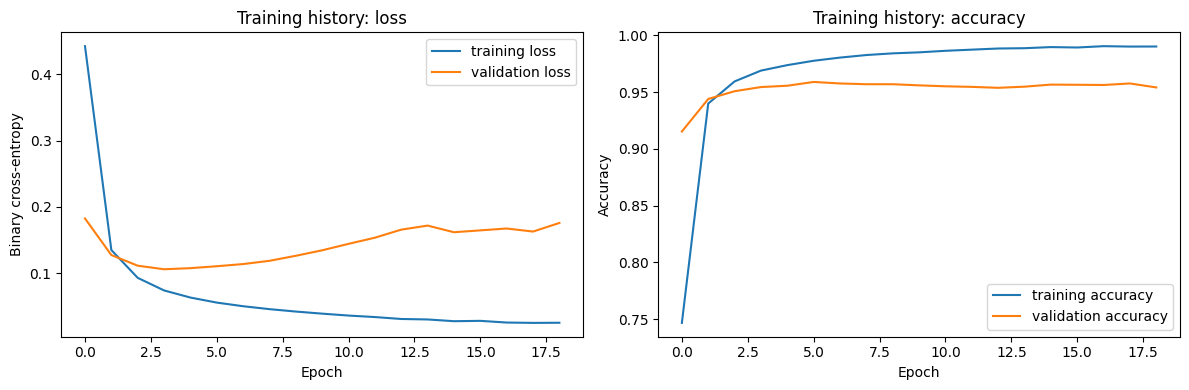

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="training loss")
axes[0].plot(history.history["val_loss"], label="validation loss")
axes[0].set_title("Training history: loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="training accuracy")
axes[1].plot(history.history["val_accuracy"], label="validation accuracy")
axes[1].set_title("Training history: accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Explicit quadratic 2-XOR model

The product

\[
(w_1^T\phi)(w_2^T\phi)
\]

contains linear terms and pairwise products of the 64 parity features. A full degree-2 polynomial expansion contains

\[
1 + 64 + \binom{64+1}{2} = 2145
\]

columns. But each parity feature is either \(-1\) or \(+1\), so \(\phi_i^2=1\). The 64 square columns duplicate the constant column and are redundant. This implementation therefore constructs a reduced feature matrix with

\[
1 + 64 + \binom{64}{2} = 1 + 64 + 2016 = 2081
\]

columns: one constant, 64 linear terms, and 2,016 unique pairwise interactions. Logistic regression is then linear in this expanded quadratic feature space.

In [13]:
def make_quadratic_features(X_in: np.ndarray):
    """Build [1, x_i, x_i*x_j (i < j)] without redundant x_i**2 columns."""
    n_samples, n_features = X_in.shape
    n_interactions = n_features * (n_features - 1) // 2
    n_columns = 1 + n_features + n_interactions

    X_quad = np.empty((n_samples, n_columns), dtype=np.float32)
    feature_names = ["bias"] + [f"phi_{i + 1}" for i in range(n_features)]

    X_quad[:, 0] = 1.0
    X_quad[:, 1 : 1 + n_features] = X_in

    column = 1 + n_features
    for i in range(n_features):
        for j in range(i + 1, n_features):
            X_quad[:, column] = X_in[:, i] * X_in[:, j]
            feature_names.append(f"phi_{i + 1}*phi_{j + 1}")
            column += 1

    return X_quad, feature_names


X_quad, quadratic_feature_names = make_quadratic_features(X)
print("Original parity features:", X.shape)
print("Reduced explicit quadratic features:", X_quad.shape)
print("Expected columns:", 1 + 64 + (64 * 63 // 2))
print("First 15 feature names:", quadratic_feature_names[:15])

assert X_quad.shape[1] == 2081

Original parity features: (60000, 64)
Reduced explicit quadratic features: (60000, 2081)
Expected columns: 2081
First 15 feature names: ['bias', 'phi_1', 'phi_2', 'phi_3', 'phi_4', 'phi_5', 'phi_6', 'phi_7', 'phi_8', 'phi_9', 'phi_10', 'phi_11', 'phi_12', 'phi_13', 'phi_14']


In [14]:
X_quad_train = X_quad[train_idx]
X_quad_val = X_quad[val_idx]
# Keep the test slice available, but do not evaluate it until the final section.

quadratic_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    C=1.0,
    fit_intercept=False,  # X_quad already includes an explicit constant feature.
    random_state=RANDOM_STATE,
)
quadratic_model.fit(X_quad_train, y_train)
quadratic_val_pred = quadratic_model.predict(X_quad_val)
validation_rows.append(
    metric_row("Logistic regression (explicit quadratic features)", y_val, quadratic_val_pred)
)

### Optional experiment: polynomial-kernel SVM

A degree-2 polynomial-kernel SVM is another way to model interactions without explicitly storing every quadratic column. It can be expensive on tens of thousands of samples, so it is disabled by default. Enable the flag below when runtime and memory permit. If enabled, it is assessed on validation data only.

In [ ]:
RUN_POLYNOMIAL_SVM = False  # Set True to run this optional, potentially slow experiment.
poly_svm = None

if RUN_POLYNOMIAL_SVM:
    from sklearn.svm import SVC

    poly_svm = SVC(kernel="poly", degree=2, C=1.0, coef0=1.0)
    poly_svm.fit(X_train, y_train)
    poly_val_pred = poly_svm.predict(X_val)
    validation_rows.append(metric_row("Polynomial-kernel SVM (degree 2)", y_val, poly_val_pred))

## 10. Validation comparison and final test evaluation

The validation table compares candidate models using the same validation rows. Use validation results to understand the trade-off and settle the candidate configurations. The held-out test set remains untouched until this point.

,Model,Accuracy,Precision,Recall,F1
0,Logistic regression (explicit quadratic features),0.9625,0.9652,0.9637,0.9644
1,Dense neural network,0.9545,0.9614,0.9520,0.9567
2,Majority-class baseline,0.5278,0.5278,1.0000,0.6910
3,Logistic regression (64 parity features),0.5007,0.5182,0.7682,0.6189


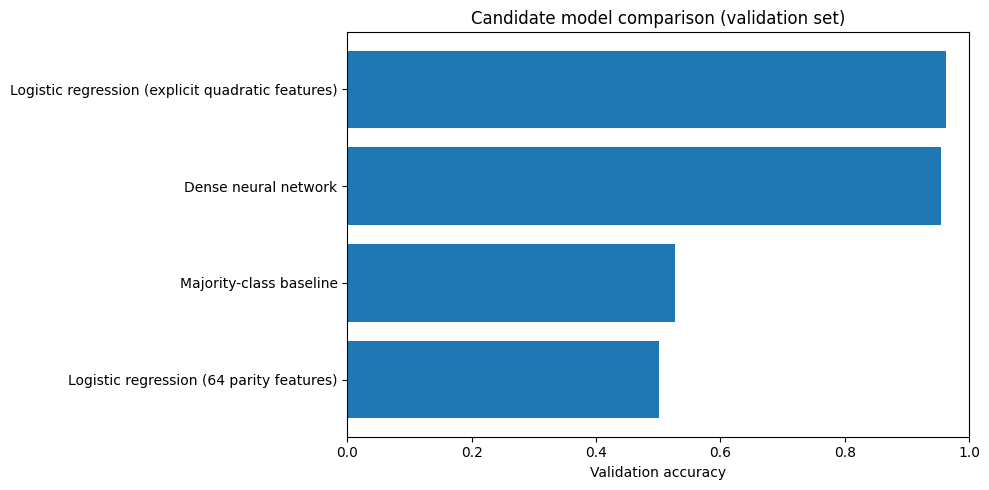

In [15]:
validation_results = (
    pd.DataFrame(validation_rows)
      .sort_values("Accuracy", ascending=False)
      .reset_index(drop=True)
)
display(validation_results.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1": "{:.4f}",
}))

plot_data = validation_results.sort_values("Accuracy", ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(plot_data["Model"], plot_data["Accuracy"])
plt.xlim(0, 1)
plt.xlabel("Validation accuracy")
plt.title("Candidate model comparison (validation set)")
plt.tight_layout()
plt.show()

### Final test protocol

The dense neural network and explicit quadratic model are the two main approaches of interest in this project, so both are reported once on the held-out test set. Do not tune hyperparameters based on these test scores. If additional iterations are needed, return to the training/validation workflow and create a new final test set for the final report.

In [16]:
# First evaluation of the held-out test set for the two primary model families.
keras_test_prob = keras_model.predict(X_test, verbose=0).ravel()
keras_test_pred = (keras_test_prob >= 0.5).astype(np.int8)

X_quad_test = X_quad[test_idx]
quadratic_test_pred = quadratic_model.predict(X_quad_test)

test_predictions = {
    "Dense neural network": keras_test_pred,
    "Logistic regression (explicit quadratic features)": quadratic_test_pred,
}

test_rows = [metric_row(name, y_test, pred) for name, pred in test_predictions.items()]
test_results = pd.DataFrame(test_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(test_results.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1": "{:.4f}",
}))

,Model,Accuracy,Precision,Recall,F1
0,Logistic regression (explicit quadratic features),0.9670,0.9699,0.9675,0.9687
1,Dense neural network,0.9605,0.9651,0.9599,0.9625


Model selected for the detailed report based on validation accuracy: Logistic regression (explicit quadratic features)

Classification report on the held-out test set:
              precision    recall  f1-score   support

           0     0.9637    0.9665    0.9651      2833
           1     0.9699    0.9675    0.9687      3167

    accuracy                         0.9670      6000
   macro avg     0.9668    0.9670    0.9669      6000
weighted avg     0.9670    0.9670    0.9670      6000



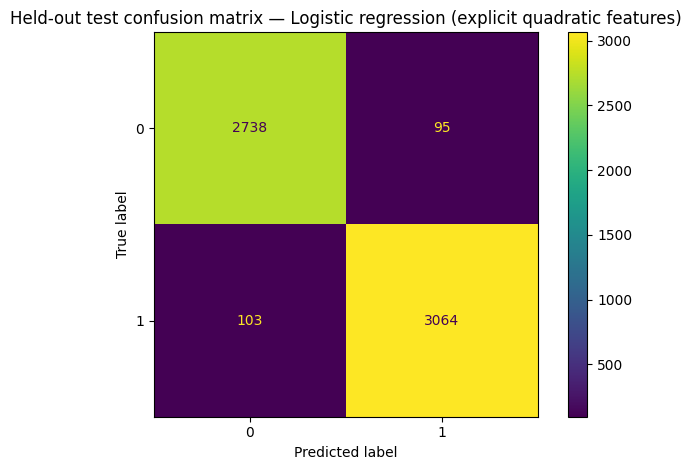

In [17]:
# Select the displayed confusion matrix by validation accuracy, not test accuracy.
primary_names = {
    "Dense neural network",
    "Logistic regression (explicit quadratic features)",
}
primary_validation = validation_results[validation_results["Model"].isin(primary_names)]
best_by_validation = primary_validation.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
selected_test_pred = test_predictions[best_by_validation]

print("Model selected for the detailed report based on validation accuracy:", best_by_validation)
print("\nClassification report on the held-out test set:")
print(classification_report(y_test, selected_test_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_test, selected_test_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
display.plot(values_format="d")
plt.title(f"Held-out test confusion matrix — {best_by_validation}")
plt.tight_layout()
plt.show()

## 11. Interpretation, limitations, and next steps

### How to explain the project in an interview

> “I modeled a 64-bit 2-XOR Arbiter PUF from challenge–response data. I first parsed and aggregated the raw records, transformed each hexadecimal challenge into ±1 challenge bits, and generated the standard APUF parity representation. I established a linear baseline, then compared a dense neural network—which learns nonlinear relationships implicitly—with logistic regression trained on explicit pairwise quadratic interactions. I used validation data for model comparison and held out a separate test set for final evaluation.”

Replace the high-level description with the metrics produced by a fresh run of this notebook; do not quote historical scores if you change the label aggregation, dataset, split, or model settings.

### Limitations to be transparent about

- **Response encoding assumption:** the aggregation treats each response token as a 32-bit word. Validate this interpretation against the dataset documentation.
- **Bit ordering:** challenge-bit order affects parity features. Confirm the encoding convention when comparing results across implementations.
- **Dataset scope:** a random split tests generalization to held-out CRPs from the same dataset, not necessarily to a different device or acquisition setup.
- **Learned predictor versus physical recovery:** good response prediction is not the same as estimating the true physical delay weights of both component APUFs.
- **Reproducibility:** results may vary with package versions, runtime, hardware, data interpretation, and hyperparameters.

### Next improvements

1. Verify the raw response encoding and challenge order from the dataset documentation.
2. Run an ablation with and without low-reliability challenges, using the same split strategy.
3. Tune model hyperparameters using validation data only.
4. Add ROC-AUC and precision–recall analysis if class balance or error costs make them informative.
5. Repeat the experiment with a separate dataset or device to test whether the learned behavior generalizes.

### Final checklist

- [ ] Raw data source and terms are documented.
- [ ] The response-label interpretation is verified.
- [ ] The notebook runs top-to-bottom from a clean runtime.
- [ ] Test data was not used for early stopping or model selection.
- [ ] The final metrics shown in the README match a fresh notebook run.